# TP 4 — Architecture Transformer
## Partie 1 — Prédiction de séries temporelles

In [1]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from torch import nn
from pathlib import Path
import copy
from IPython.display import display
torch.manual_seed(42); torch.set_num_threads(2)
Path('captures').mkdir(exist_ok=True)
def fig(name):
    plt.tight_layout(); plt.savefig('captures/'+name,dpi=140); plt.show(); plt.close()

In [2]:
import torch
import torch.nn as nn
torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
# Un RNN attend : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

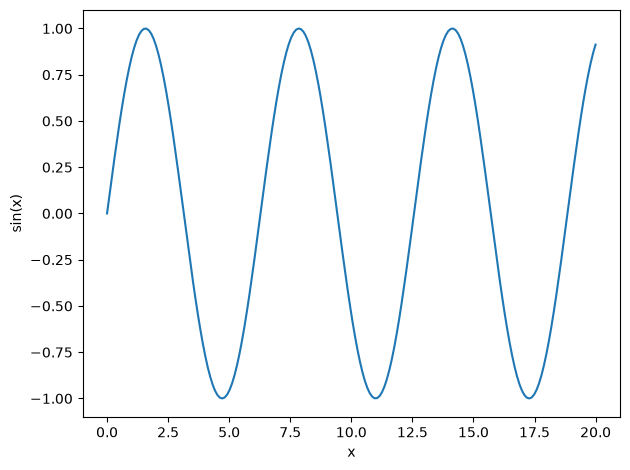

In [3]:
plt.plot(periode,serie); plt.xlabel('x'); plt.ylabel('sin(x)'); fig('sinus.png')

Les dix valeurs précédentes servent à prédire la suivante. Le RNN utilise un état caché, le LSTM une mémoire à portes et le Transformer une attention avec encodage positionnel.

                  MSE       MAE
RNN          0.000028  0.004562
LSTM         0.000010  0.002636
Transformer  0.000052  0.006318


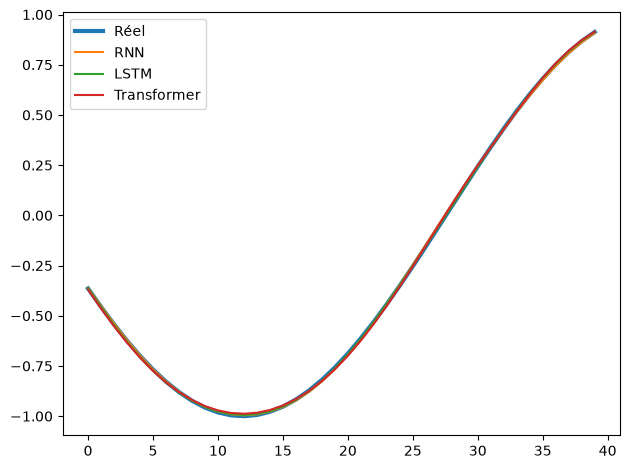

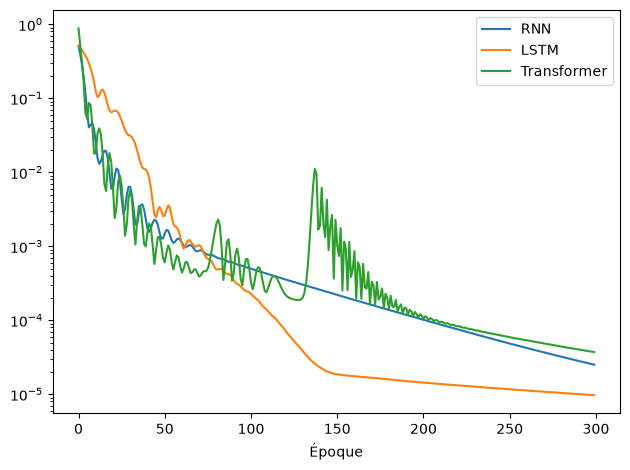

In [4]:
class Recurrent(nn.Module):
    def __init__(self,kind):
        super().__init__(); self.r=kind(1,16,batch_first=True); self.out=nn.Linear(16,1)
    def forward(self,x): return self.out(self.r(x)[0][:,-1])
class SequenceTransformer(nn.Module):
    def __init__(self,length=10,dim=16,heads=2,layers=1,ff=32,dropout=0.):
        super().__init__(); self.proj=nn.Linear(1,dim); self.pos=nn.Embedding(length,dim)
        self.enc=nn.TransformerEncoder(nn.TransformerEncoderLayer(dim,heads,ff,dropout,batch_first=True),layers)
        self.out=nn.Linear(dim,1)
    def forward(self,x): return self.out(self.enc(self.proj(x)+self.pos(torch.arange(x.size(1),device=x.device)))[:,-1])
models={'RNN':Recurrent(nn.RNN),'LSTM':Recurrent(nn.LSTM),'Transformer':SequenceTransformer()}
results={}; curves={}; preds={}
for name,model in models.items():
    opt=torch.optim.Adam(model.parameters(),lr=.01); curves[name]=[]
    for epoch in range(300):
        model.train(); opt.zero_grad(); loss=nn.functional.mse_loss(model(X_train),y_train)
        loss.backward(); opt.step(); curves[name].append(loss.item())
    model.eval()
    with torch.no_grad(): pred=model(X_test)
    preds[name]=pred.numpy().ravel(); results[name]={'MSE':nn.functional.mse_loss(pred,y_test).item(),'MAE':(pred-y_test).abs().mean().item()}
print(pd.DataFrame(results).T)
plt.plot(y_test.numpy(),label='Réel',linewidth=3)
for name,pred in preds.items(): plt.plot(pred,label=name)
plt.legend(); fig('predictions.png')
for name,losses in curves.items(): plt.plot(losses,label=name)
plt.yscale('log'); plt.legend(); plt.xlabel('Époque'); fig('pertes.png')

## GPT-2 et BERT préentraînés
GPT prédit la suite du texte ; BERT retrouve un token masqué. Téléchargement nécessaire au premier lancement.

In [5]:
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM

    # --------------------------------------------------
    # 1. Charger le tokenizer et le modèle préentraîné
    # --------------------------------------------------

    nom_modele = "gpt2"

    tokenizer = AutoTokenizer.from_pretrained(nom_modele)
    modele = AutoModelForCausalLM.from_pretrained(nom_modele)

    # GPT-2 ne possède pas de token de padding dédié.
    tokenizer.pad_token = tokenizer.eos_token
    modele.config.pad_token_id = tokenizer.pad_token_id

    modele.eval()

    # --------------------------------------------------
    # 2. Transformer le texte en tokens
    # --------------------------------------------------

    # GPT-2 est principalement entraîné sur de l'anglais.
    texte = "Artificial intelligence can help people"

    entrees = tokenizer(
        texte,
        return_tensors="pt"
    )

    print("Dimensions de l'entrée :", entrees["input_ids"].shape)
    # (1, nombre de tokens du texte)

    # --------------------------------------------------
    # 3. Générer la suite, un token après l'autre
    # --------------------------------------------------

    with torch.no_grad():
        sortie = modele.generate(
            **entrees,
            max_new_tokens=50,       # Générer au maximum 50 tokens
            do_sample=True,          # Tirage aléatoire des tokens
            temperature=0.8,         # Contrôler la diversité
            top_p=0.9,               # Limiter les candidats probables
            pad_token_id=tokenizer.pad_token_id
        )

    # --------------------------------------------------
    # 4. Reconvertir les tokens en texte
    # --------------------------------------------------

    texte_genere = tokenizer.decode(
        sortie[0],
        skip_special_tokens=True
    )

    print("\nTexte généré :")
    print(texte_genere)
except (ImportError,OSError,RuntimeError) as e:
    print("Modèle indisponible :",e)

c:\IA Générative Multi Modale\tp4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:01<00:00, 89.81it/s]


Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people find solutions to a myriad of problems. It could be an option for the public at large.

In the meantime, the question is whether the AI will be able to provide us with a new way of interacting with the world.


In [6]:
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForMaskedLM

    # --------------------------------------------------
    # 1. Charger le tokenizer et le modèle préentraîné
    # --------------------------------------------------

    nom_modele = "bert-base-multilingual-cased"

    tokenizer = AutoTokenizer.from_pretrained(nom_modele)
    modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

    modele.eval()

    # --------------------------------------------------
    # 2. Préparer un texte avec un token masqué
    # --------------------------------------------------

    texte = f"Rabat est la {tokenizer.mask_token} Maroc."

    entrees = tokenizer(
        texte,
        return_tensors="pt"
    )

    print("Texte :", texte)
    print("Dimensions de l'entrée :", entrees["input_ids"].shape)
    # (1, nombre de tokens du texte)

    # Repérer la position du masque dans la séquence
    position_masque = (
        entrees["input_ids"][0] == tokenizer.mask_token_id
    ).nonzero(as_tuple=True)[0].item()

    # --------------------------------------------------
    # 3. Prédire le token masqué
    # --------------------------------------------------

    with torch.no_grad():
        sortie = modele(**entrees)

    # sortie.logits : (1, nombre de tokens, taille du vocabulaire)
    scores = sortie.logits[0, position_masque, :]

    # Transformer les scores en probabilités
    probabilites = torch.softmax(scores, dim=-1)

    # Sélectionner les 5 tokens les plus probables
    top_probabilites, top_indices = torch.topk(probabilites, k=5)

    # --------------------------------------------------
    # 4. Afficher les propositions
    # --------------------------------------------------

    print("\nPropositions de BERT :")

    for probabilite, indice in zip(top_probabilites, top_indices):
        token = tokenizer.decode([indice.item()]).strip()

        phrase = texte.replace(tokenizer.mask_token, token)

        print(f"{probabilite.item():.2%} | {phrase}")
except (ImportError,OSError,RuntimeError) as e:
    print("Modèle indisponible :",e)

Loading weights: 100%|██████████| 202/202 [00:01<00:00, 192.83it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] Maroc.
Dimensions de l'entrée : torch.Size([1, 8])

Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


## Partie 2 — Exercice 1 : consommation électrique
Préparation UCI : moyenne horaire, au moins 45 mesures par heure, normalisation sur le train uniquement et fenêtres de 24 heures.

In [7]:
ENERGY_AVAILABLE=Path("household_power_consumption.txt").exists()
if ENERGY_AVAILABLE:
    import numpy as np
    import pandas as pd
    import torch
    from torch.utils.data import TensorDataset, DataLoader

    df = pd.read_csv(
        "household_power_consumption.txt",
        sep=";",
        na_values=["?"],
        low_memory=False,
    )

    df["datetime"] = pd.to_datetime(
        df["Date"] + " " + df["Time"],
        format="%d/%m/%Y %H:%M:%S",
    )

    puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
    puissance.index = pd.DatetimeIndex(df["datetime"])

    # Puissance moyenne horaire : conserver les heures suffisamment renseignées.
    horaire = puissance.resample("h").agg(["mean", "count"])
    serie = horaire["mean"].where(horaire["count"] >= 45)

    # Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
    n = len(serie)
    fin_train = int(0.70 * n)
    fin_val = int(0.85 * n)

    # Normalisation calculée uniquement sur l'entraînement.
    moyenne = serie.iloc[:fin_train].mean()
    ecart_type = serie.iloc[:fin_train].std()
    valeurs = ((serie - moyenne) / ecart_type).to_numpy()

    # Une entrée contient 24 heures consécutives.
    # Écarter les fenêtres comportant des valeurs manquantes.
    fenetre = 24
    X, y, dates_cibles = [], [], []

    for i in range(fenetre, n):
        sequence = valeurs[i - fenetre:i]
        cible = valeurs[i]

        if np.isfinite(sequence).all() and np.isfinite(cible):
            X.append(sequence)
            y.append(cible)
            dates_cibles.append(i)

    X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
    y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
    dates_cibles = np.array(dates_cibles)

    train_mask = dates_cibles < fin_train
    val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
    test_mask = dates_cibles >= fin_val

    train_loader = DataLoader(
        TensorDataset(X[train_mask], y[train_mask]),
        batch_size=64,
        shuffle=True,
    )
    val_loader = DataLoader(
        TensorDataset(X[val_mask], y[val_mask]),
        batch_size=64,
    )
    test_loader = DataLoader(
        TensorDataset(X[test_mask], y[test_mask]),
        batch_size=64,
    )
else:
    print("Dataset UCI absent : voir README.")

1 0.3995987198123547
2 0.3913378307929754
3 0.3931533377964033
4 0.38996796443804854
5 0.3879331913115151
6 0.38489231367001764
7 0.3844320869370322
8 0.3826579523029939
9 0.3849909414073248
10 0.3864527799699162
11 0.3880564893806316
12 0.380953365321399
13 0.39038262642746063
14 0.3842523717861379
15 0.38427100938254305
16 0.38693269345427295
17 0.38613614622764453
18 0.3818252029086839
19 0.3947271375161742
20 0.38116219301303006
               MAE kW   RMSE kW
Transformer  0.341689  0.498874
Persistance  0.389198  0.588385
Journalière  0.513277  0.763876


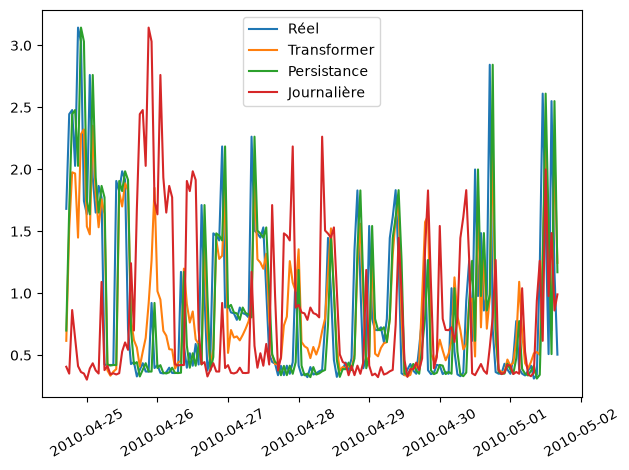

In [8]:
class EnergyTransformer(SequenceTransformer):
    def __init__(self): super().__init__(24,32,4,2,128,.1)
if ENERGY_AVAILABLE:
    model=EnergyTransformer(); opt=torch.optim.Adam(model.parameters(),lr=.001); best=float('inf')
    for epoch in range(20):
        model.train()
        for a,b in train_loader:
            opt.zero_grad(); loss=nn.functional.mse_loss(model(a),b); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad(): val=sum(nn.functional.mse_loss(model(a),b,reduction='sum').item() for a,b in val_loader)/len(val_loader.dataset)
        if val<best: best=val; state=copy.deepcopy(model.state_dict())
        print(epoch+1,val)
    model.load_state_dict(state); model.eval()
    with torch.no_grad(): pred=torch.cat([model(a) for a,b in test_loader]).numpy().ravel()
    actual=y[test_mask].numpy().ravel()*ecart_type+moyenne
    estimates={'Transformer':pred*ecart_type+moyenne,'Persistance':X[test_mask,-1,0].numpy()*ecart_type+moyenne,'Journalière':X[test_mask,0,0].numpy()*ecart_type+moyenne}
    print(pd.DataFrame({k:{'MAE kW':np.mean(abs(v-actual)),'RMSE kW':np.sqrt(np.mean((v-actual)**2))} for k,v in estimates.items()}).T)
    dates=serie.index[dates_cibles[test_mask]]; period=dates<dates[0]+pd.Timedelta(days=7)
    plt.plot(dates[period],actual[period],label='Réel')
    for k,v in estimates.items(): plt.plot(dates[period],v[period],label=k)
    plt.xticks(rotation=30); plt.legend(); fig('energie.png')

### Questions
- Comparer MAE et RMSE : le meilleur modèle minimise ces erreurs, à vérifier après exécution.
- Une fenêtre de 168 heures couvre la semaine mais augmente le coût.
- Heure et jour renseignent sur les habitudes de consommation.
- Normaliser sur le train évite une fuite de données futures.
- Pour obtenir des kWh, intégrer la puissance dans le temps (mesures en kW multipliées par 1/60 h), en tenant compte des valeurs manquantes.

## Exercice 2 — Mini-GPT
Tokenisation par caractères, deux blocs pré-normalisés et attention causale.

Perte validation: 1.314361333847046
Test causal réussi


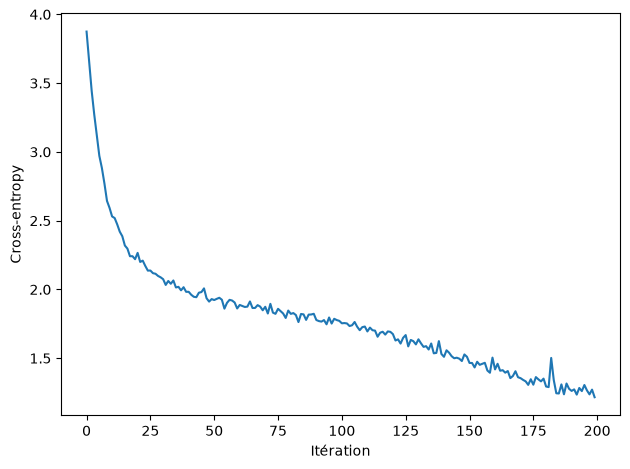

KeyError: 'L'

In [10]:
text=Path('household_power_consumption.txt').read_text(encoding='utf-8'); chars=sorted(set(text)); stoi={c:i for i,c in enumerate(chars)}; itos=dict(enumerate(chars))
tokens=torch.tensor([stoi[c] for c in text]); V=len(chars); T=64
cut=int(.85*len(tokens)); tr,va=tokens[:cut],tokens[cut:]
def batch(data,size=32):
    starts=torch.randint(len(data)-T,(size,))
    return torch.stack([data[i:i+T] for i in starts]),torch.stack([data[i+1:i+T+1] for i in starts])
class GPTBlock(nn.Module):
    def __init__(self):
        super().__init__(); self.n1=nn.LayerNorm(64); self.n2=nn.LayerNorm(64); self.att=nn.MultiheadAttention(64,4,batch_first=True)
        self.mlp=nn.Sequential(nn.Linear(64,256),nn.GELU(),nn.Linear(256,64))
    def forward(self,x):
        h=self.n1(x); mask=torch.ones(x.size(1),x.size(1),dtype=torch.bool,device=x.device).triu(1)
        x=x+self.att(h,h,h,attn_mask=mask,need_weights=False)[0]; return x+self.mlp(self.n2(x))
class MiniGPT(nn.Module):
    def __init__(self):
        super().__init__(); self.emb=nn.Embedding(V,64); self.pos=nn.Embedding(T,64); self.blocks=nn.Sequential(GPTBlock(),GPTBlock()); self.out=nn.Sequential(nn.LayerNorm(64),nn.Linear(64,V))
    def forward(self,x): return self.out(self.blocks(self.emb(x)+self.pos(torch.arange(x.size(1)))))
gpt=MiniGPT(); opt=torch.optim.AdamW(gpt.parameters(),lr=.001); losses=[]
for step in range(200):
    gpt.train(); a,b=batch(tr); opt.zero_grad(); loss=nn.functional.cross_entropy(gpt(a).reshape(-1,V),b.reshape(-1)); loss.backward(); opt.step(); losses.append(loss.item())
gpt.eval()
with torch.no_grad():
    a,b=batch(va); print('Perte validation:',nn.functional.cross_entropy(gpt(a).reshape(-1,V),b.reshape(-1)).item())
    changed=a.clone(); changed[:,32]=(changed[:,32]+1)%V
    torch.testing.assert_close(gpt(a)[:,:32],gpt(changed)[:,:32],atol=1e-5,rtol=1e-5)
print('Test causal réussi'); plt.plot(losses); plt.xlabel('Itération'); plt.ylabel('Cross-entropy'); fig('gpt.png')
@torch.no_grad()
def generate(prompt,temp):
    ids=torch.tensor([[stoi[c] for c in prompt]])
    for _ in range(200):
        probs=(gpt(ids[:,-T:])[:,-1]/temp).softmax(-1); ids=torch.cat([ids,torch.multinomial(probs,1)],dim=1)
    return ''.join(itos[i] for i in ids[0].tolist())
for temp in [.5,1.,1.5]: print(temp,generate('Le ',temp))

Sans masque causal, le modèle peut voir la cible future. La température faible favorise les caractères probables, la température élevée augmente la diversité. Le décalage apprend à prédire le caractère suivant.

## Exercice 3 — Mini-BERT
Masquage dynamique de 15 % environ, règle 80/10/10, padding à 32 tokens et attention bidirectionnelle.

In [ ]:
PAD,UNK,CLS,SEP,MASK=range(5)
train=[f'le {a} {b} dans le {c}' for a in ['chat','chien','lapin','renard'] for b in ['dort','joue','marche'] for c in ['jardin','salon','parc']]
val=['le chat joue dans le parc','le chien dort dans le salon','le lapin marche dans le jardin','le renard joue dans le jardin']; train=[s for s in train if s not in val]
vocab={w:i+5 for i,w in enumerate(sorted(set(' '.join(train).split())))}; rev={i:w for w,i in vocab.items()}; rev.update(dict(enumerate(['[PAD]','[UNK]','[CLS]','[SEP]','[MASK]']))); VB=len(vocab)+5
def encode(s):
    ids=[CLS]+[vocab.get(w,UNK) for w in s.split()[:30]]+[SEP]; return ids+[PAD]*(32-len(ids))
train_ids=torch.tensor([encode(s) for s in train]); val_ids=torch.tensor([encode(s) for s in val])
def corrupt(ids):
    ordinary=ids>=5; selected=(torch.rand(ids.shape)<.15)&ordinary
    for i in range(len(ids)):
        candidates=ordinary[i].nonzero().flatten()
        if len(candidates) and not selected[i].any(): selected[i,candidates[torch.randint(len(candidates),(1,))]]=True
    labels=ids.clone(); labels[~selected]=-100; masked=ids.clone(); r=torch.rand(ids.shape)
    masked[selected&(r<.8)]=MASK; replace=selected&(r>=.8)&(r<.9); masked[replace]=torch.randint(5,VB,(int(replace.sum()),))
    return masked,labels,ids==PAD
class MiniBERT(nn.Module):
    def __init__(self):
        super().__init__(); self.emb=nn.Embedding(VB,64); self.pos=nn.Embedding(32,64)
        self.enc=nn.TransformerEncoder(nn.TransformerEncoderLayer(64,4,256,.1,batch_first=True),2,enable_nested_tensor=False); self.out=nn.Linear(64,VB)
    def forward(self,x,pad): return self.out(self.enc(self.emb(x)+self.pos(torch.arange(x.size(1))),src_key_padding_mask=pad))
bert=MiniBERT(); opt=torch.optim.AdamW(bert.parameters(),lr=.001); losses=[]
for epoch in range(60):
    bert.train(); a,b,pad=corrupt(train_ids); opt.zero_grad(); loss=nn.functional.cross_entropy(bert(a,pad).reshape(-1,VB),b.flatten(),ignore_index=-100); loss.backward(); opt.step(); losses.append(loss.item())
bert.eval()
with torch.no_grad():
    a,b,pad=corrupt(val_ids); logits=bert(a,pad); selected=b!=-100
    print('Exactitude validation:',(logits.argmax(-1)[selected]==b[selected]).float().mean().item())
    changed=a.clone(); changed[pad]=MASK; torch.testing.assert_close(logits[~pad],bert(changed,pad)[~pad],atol=1e-5,rtol=1e-5); print('Test padding réussi')
    for sentence in val[:3]:
        ids=torch.tensor([encode(sentence)]); pad=ids==PAD; ids[0,2]=MASK; top=bert(ids,pad)[0,2].softmax(-1).topk(3)
        print(sentence,[(rev[i],round(v,3)) for i,v in zip(top.indices.tolist(),top.values.tolist())])
plt.plot(losses); plt.xlabel('Époque'); plt.ylabel('Cross-entropy'); fig('bert.png')

Exactitude validation: 1.0
Test padding réussi
le chat joue dans le parc [('lapin', 0.36), ('renard', 0.233), ('chat', 0.207)]
le chien dort dans le salon [('lapin', 0.358), ('renard', 0.233), ('chat', 0.213)]
le lapin marche dans le jardin [('lapin', 0.339), ('chat', 0.225), ('renard', 0.224)]


/tmp/ipykernel_1554/2060881539.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig('captures/'+name,dpi=140); plt.show(); plt.close()


BERT utilise les deux côtés du contexte. La perte ne concerne que les positions sélectionnées, même si le mot est resté inchangé. BERT reconstruit des mots masqués, tandis que GPT prédit la suite. Le corpus réduit limite la généralisation.